In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [ ]:
df=pd.read_csv("/content/weatherHistory.csv")
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [ ]:
df.isnull().sum()

,0
Formatted Date,0
Summary,0
Precip Type,517
Temperature (C),0
Apparent Temperature (C),0
Humidity,0
Wind Speed (km/h),0
Wind Bearing (degrees),0
Visibility (km),0
Loud Cover,0


In [ ]:
df.shape

(96453, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


In [ ]:
df.select_dtypes(include=['object'])

,Formatted Date,Summary,Precip Type,Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,Partly cloudy throughout the day.
...,...,...,...,...
96448,2016-09-09 19:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy starting in the morning.
96449,2016-09-09 20:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy starting in the morning.
96450,2016-09-09 21:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy starting in the morning.
96451,2016-09-09 22:00:00.000 +0200,Partly Cloudy,rain,Partly cloudy starting in the morning.


In [ ]:
df.drop("Formatted Date",axis=1)

,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
...,...,...,...,...,...,...,...,...,...,...,...
96448,Partly Cloudy,rain,26.016667,26.016667,0.43,10.9963,31.0,16.1000,0.0,1014.36,Partly cloudy starting in the morning.
96449,Partly Cloudy,rain,24.583333,24.583333,0.48,10.0947,20.0,15.5526,0.0,1015.16,Partly cloudy starting in the morning.
96450,Partly Cloudy,rain,22.038889,22.038889,0.56,8.9838,30.0,16.1000,0.0,1015.66,Partly cloudy starting in the morning.
96451,Partly Cloudy,rain,21.522222,21.522222,0.60,10.5294,20.0,16.1000,0.0,1015.95,Partly cloudy starting in the morning.


In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col]=le.fit_transform(df[col])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  int64  
 1   Summary                   96453 non-null  int64  
 2   Precip Type               96453 non-null  int64  
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  int64  
dtypes: float64(8), int64(4)
memory usage: 8.8 MB


In [ ]:
x=df.drop(['Summary'],axis=1)
y=df['Summary']

In [ ]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [ ]:
df.isnull().sum()

,0
Formatted Date,0
Summary,0
Precip Type,0
Temperature (C),0
Apparent Temperature (C),0
Humidity,0
Wind Speed (km/h),0
Wind Bearing (degrees),0
Visibility (km),0
Loud Cover,0


In [ ]:
x

,Formatted Date,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2159,0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,197
1,2160,0,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,197
2,2161,0,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,197
3,2162,0,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,197
4,2163,0,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,197
...,...,...,...,...,...,...,...,...,...,...,...
96448,93711,0,26.016667,26.016667,0.43,10.9963,31.0,16.1000,0.0,1014.36,170
96449,93712,0,24.583333,24.583333,0.48,10.0947,20.0,15.5526,0.0,1015.16,170
96450,93713,0,22.038889,22.038889,0.56,8.9838,30.0,16.1000,0.0,1015.66,170
96451,93714,0,21.522222,21.522222,0.60,10.5294,20.0,16.1000,0.0,1015.95,170


In [ ]:
sc=StandardScaler()
x=sc.fit_transform(x)
x

array([[-1.65459023, -0.35501138, -0.25759902, ...,  0.        ,
         0.10168518,  1.20287545],
       [-1.6545543 , -0.35501138, -0.26981351, ...,  0.        ,
         0.1059598 ,  1.20287545],
       [-1.65451837, -0.35501138, -0.26748694, ...,  0.        ,
         0.10861007,  1.20287545],
       ...,
       [ 1.63475782, -0.35501138,  1.0580761 , ...,  0.        ,
         0.10621628,  0.72308959],
       [ 1.63479374, -0.35501138,  1.00398335, ...,  0.        ,
         0.10869557,  0.72308959],
       [ 1.63482967, -0.35501138,  0.89056308, ...,  0.        ,
         0.11049091,  0.72308959]])

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=47)

In [ ]:
x_train.shape[1]

11

In [ ]:
model=Sequential([
    Dense(64,activation='relu',input_shape=(x_train.shape[1],)),
    Dense(32,activation='relu'),
    Dense(27,activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history=model.fit(x_train,y_train,epochs=30,validation_data=(x_test,y_test))

Epoch 1/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6199 - loss: 0.8946 - val_accuracy: 0.6189 - val_loss: 0.9029
Epoch 2/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6204 - loss: 0.8913 - val_accuracy: 0.6211 - val_loss: 0.8970
Epoch 3/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.6209 - loss: 0.8879 - val_accuracy: 0.6173 - val_loss: 0.9045
Epoch 4/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6207 - loss: 0.8854 - val_accuracy: 0.6222 - val_loss: 0.9015
Epoch 5/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.6213 - loss: 0.8840 - val_accuracy: 0.6217 - val_loss: 0.8934
Epoch 6/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6225 - loss: 0.8808 - val_accuracy: 0.6219 - val_loss: 0.8958
Epoch 7/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6234 - loss: 0.8799 - val_accuracy: 0.6256 - val_loss: 0.8905
Epoch 8/30
2412/2412 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.6242 - loss: 0.8785 -

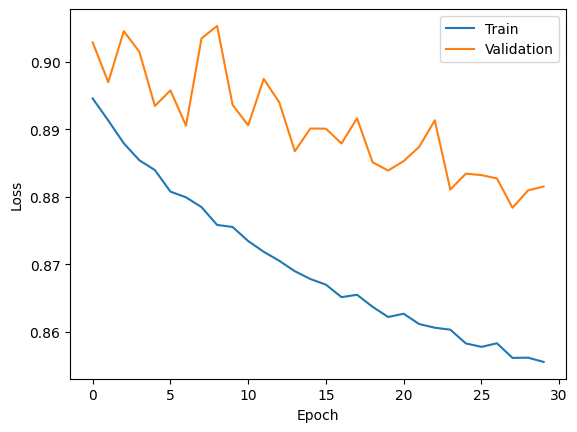

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()